
# Iris Flower Classification

## Project Idea
This project uses machine learning to predict the species of an Iris
flower from four measurements: sepal length, sepal width, petal
length, and petal width.

## Objective
To train and compare a Decision Tree classifier and a
K-Nearest Neighbors (KNN) classifier.

## Usefulness
The project demonstrates how machine learning can learn patterns
from measurements and classify new examples.
# Iris Flower Classification

## Project Idea
This project uses machine learning to predict the species of an Iris
flower from four measurements: sepal length, sepal width, petal
length, and petal width.

## Objective
To train and compare a Decision Tree classifier and a
K-Nearest Neighbors (KNN) classifier.

## Usefulness
The project demonstrates how machine learning can learn patterns
from measurements and classify new examples.

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:

iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

print("First five rows:")
print(X.head())

print("\nTarget species:")
print(iris.target_names)

print("\nDataset shape:")
print(X.shape)

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target species:
['setosa' 'versicolor' 'virginica']

Dataset shape:
(150, 4)


In [3]:

print("Missing values in each feature:")
print(X.isnull().sum())

print("\nMissing target values:")
print(pd.isnull(y).sum())

print("\nDuplicate rows:")
print(X.duplicated().sum())

Missing values in each feature:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Missing target values:
0

Duplicate rows:
1


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 120
Testing examples: 30


In [5]:

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train, y_train)

dt_predictions = decision_tree.predict(X_test)

dt_accuracy = accuracy_score(
    y_test,
    dt_predictions
)

print("Decision Tree accuracy:", dt_accuracy)
print("Decision Tree accuracy (%):", dt_accuracy * 100)

Decision Tree accuracy: 0.9333333333333333
Decision Tree accuracy (%): 93.33333333333333


In [6]:

knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)

knn_predictions = knn.predict(X_test)

knn_accuracy = accuracy_score(
    y_test,
    knn_predictions
)

print("KNN accuracy:", knn_accuracy)
print("KNN accuracy (%):", knn_accuracy * 100)

KNN accuracy: 0.9333333333333333
KNN accuracy (%): 93.33333333333333


In [7]:

results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy": [dt_accuracy, knn_accuracy]
})

print(results)

           Model  Accuracy
0  Decision Tree  0.933333
1            KNN  0.933333


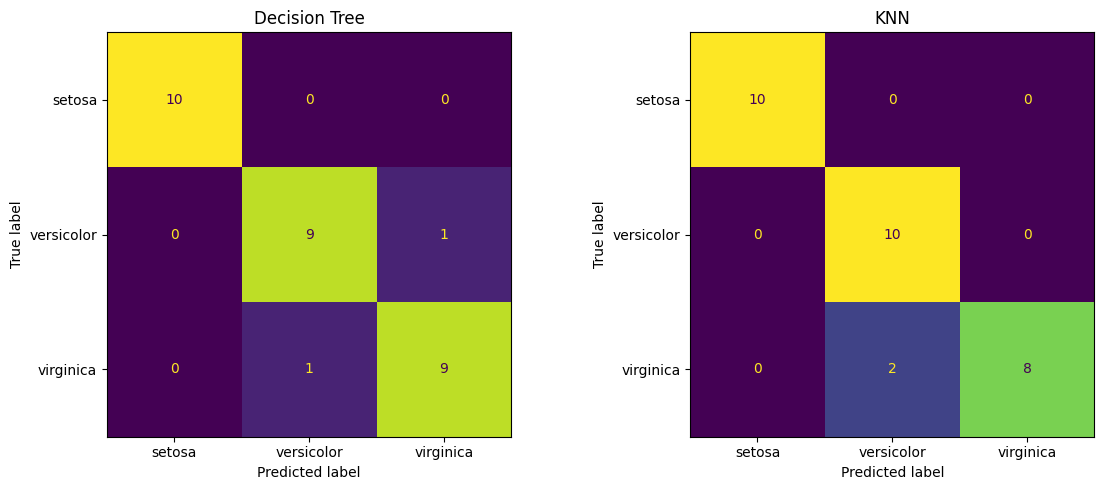

In [8]:

dt_cm = confusion_matrix(
    y_test,
    dt_predictions,
    labels=[0, 1, 2]
)

knn_cm = confusion_matrix(
    y_test,
    knn_predictions,
    labels=[0, 1, 2]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=dt_cm,
    display_labels=iris.target_names
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("Decision Tree")

ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=iris.target_names
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("KNN")

plt.tight_layout()
plt.show()

In [9]:

new_flower = [[5.1, 3.5, 1.4, 0.2]]

dt_new_prediction = decision_tree.predict(new_flower)
knn_new_prediction = knn.predict(new_flower)

print(
    "Decision Tree prediction:",
    iris.target_names[dt_new_prediction[0]]
)

print(
    "KNN prediction:",
    iris.target_names[knn_new_prediction[0]]
)

Decision Tree prediction: setosa
KNN prediction: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



## Conclusion

In this project, I trained a Decision Tree and a K-Nearest
Neighbors classifier to predict Iris flower species.

I checked the dataset for missing values, separated it into
training and testing sets, and evaluated both models using
accuracy and confusion matrices.

The model with the higher test accuracy performed better on
this particular split. The confusion matrices helped me see
which species were classified correctly and which were confused.

I learned how a machine learning workflow moves from data
preparation to training, prediction, and evaluation.